<a href="https://colab.research.google.com/github/AidaAm005/NHANES-Tobacco-Biomarkers/blob/phase-2/phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import sys
from google.colab import drive

drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/NHANES-Tobacco-Biomarkers'
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("مسیر کاری فعلی:", os.getcwd())
print("فایل‌های موجود در src:", sorted(os.listdir('src')))

Mounted at /content/drive
مسیر کاری فعلی: /content/drive/MyDrive/NHANES-Tobacco-Biomarkers
فایل‌های موجود در src: ['.ipynb_checkpoints', '__init__.py', '__pycache__', 'data_cleaner.py', 'data_loader.py', 'descriptive_stats.py', 'probability_events.py', 'survey_design.py']


In [3]:
from src.data_loader import fetch_raw_datasets, merge_datasets
from src.data_cleaner import fix_sas_zeros, audit_and_clean_special_codes
from src.survey_design import define_analytic_population

raw_datasets, _ = fetch_raw_datasets()
df_merged_raw, _ = merge_datasets(raw_datasets)
df_step1, _ = fix_sas_zeros(df_merged_raw)
df_cleaned, _ = audit_and_clean_special_codes(df_step1)
df_analytic, df_flow = define_analytic_population(df_cleaned)

print(f"حجم جمعیت تحلیلی نهایی (df_analytic): {len(df_analytic)} نفر")
assert len(df_analytic) == 4655, "خطا: حجم جمعیت تحلیلی با فاز اول همخوانی ندارد!"
print("تایید شد: جمعیت تحلیلی دقیقاً منطبق بر فاز اول است.")

حجم جمعیت تحلیلی نهایی (df_analytic): 4655 نفر
تایید شد: جمعیت تحلیلی دقیقاً منطبق بر فاز اول است.


In [4]:
import importlib
import src.probability_events as pe
importlib.reload(pe)

df_p2 = pe.add_phase2_events_and_rvs(df_analytic)
df_ev_summary, df_rv_summary = pe.verify_task1_analytic_summary(df_p2)

print("=== جدول ۱-الف: فراوانی و احتمال حاشیه‌ای رویدادهای دودویی در جمعیت تحلیلی (N=4,655) ===")
display(df_ev_summary)

print("\n=== جدول ۱-ب: بازه دقیق (کمینه، چارک‌ها و بیشینه) متغیرهای تصادفی روی جمعیت تحلیلی ===")
display(df_rv_summary)

=== جدول ۱-الف: فراوانی و احتمال حاشیه‌ای رویدادهای دودویی در جمعیت تحلیلی (N=4,655) ===


,Event,Count (n),Complement_Count,Total_N,Empirical_Prob,Percent (%)
0,A: Combustible Smoker (G3 U G4),775,3880,4655,0.1665,16.65
1,B: High Blood Cadmium (LBXBCD >= 0.5 ug/L),971,3684,4655,0.2086,20.86
2,C: Active Nicotine (LBXCOT >= 10.0 ng/mL),912,3743,4655,0.1959,19.59
3,M: Male Participants (RIAGENDR = 1),2094,2561,4655,0.4498,44.98



=== جدول ۱-ب: بازه دقیق (کمینه، چارک‌ها و بیشینه) متغیرهای تصادفی روی جمعیت تحلیلی ===


,Variable,Description,Valid_N,Min,Q1,Median,Q3,Max
0,LBXBCD,W: Blood Cadmium (ug/L),4655,0.046,0.170,0.262,0.442,7.684
1,Log10_LBXBCD,Y1: Log10 Blood Cadmium,4655,-1.337,-0.770,-0.582,-0.355,0.886
2,LBXCOT,Raw Serum Cotinine (ng/mL),4655,0.007,0.007,0.014,0.232,889.000
3,Log10_LBXCOT,Y2: Log10 Serum Cotinine,4655,-2.155,-2.155,-1.854,-0.635,2.949
4,LBXHGB,Y3: Hemoglobin (g/dL),4638,6.600,13.000,13.900,14.900,18.600
5,RIDAGEYR,Age (Years),4655,20.000,40.000,58.000,68.000,80.000


In [5]:
# جفت اصلی ۱: مصرف سیگار احتراقی (A) و کادمیوم بالای خون (B)
ct_ab_counts, ct_ab_probs = pe.compute_marginal_and_joint_tables(
    df_p2, "Event_A_Label", "Event_B_Label"
)
print("=== جدول ۲-۱ (فراوانی): جدول توافقی رویداد A (سیگار احتراقی) و رویداد B (کادمیوم >= 0.5) ===")
display(ct_ab_counts)

print("\n=== جدول ۲-۲ (احتمال مشترک و حاشیه‌ای): P(A), P(B), P(A ∩ B) ===")
display(ct_ab_probs)

# جفت مکمل ۲: مصرف سیگار احتراقی (A) و مواجهه فعال با نیکوتین (C)
ct_ac_counts, ct_ac_probs = pe.compute_marginal_and_joint_tables(
    df_p2, "Event_A_Label", "Event_C_Label"
)
print("\n=== جدول ۲-۳ (احتمال مشترک و حاشیه‌ای): رویداد A و رویداد C (کوتینین >= 10) ===")
display(ct_ac_probs)

=== جدول ۲-۱ (فراوانی): جدول توافقی رویداد A (سیگار احتراقی) و رویداد B (کادمیوم >= 0.5) ===


Event_B_Label,B: High Cadmium (>=0.5),B^c: Low Cadmium (<0.5),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,536,239,775
A^c: Non-Combustible,435,3445,3880
Total (Marginal),971,3684,4655



=== جدول ۲-۲ (احتمال مشترک و حاشیه‌ای): P(A), P(B), P(A ∩ B) ===


Event_B_Label,B: High Cadmium (>=0.5),B^c: Low Cadmium (<0.5),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,0.1151,0.0513,0.1665
A^c: Non-Combustible,0.0934,0.7401,0.8335
Total (Marginal),0.2086,0.7914,1.0000



=== جدول ۲-۳ (احتمال مشترک و حاشیه‌ای): رویداد A و رویداد C (کوتینین >= 10) ===


Event_C_Label,C: Active Nicotine (>=10),C^c: No Active Nicotine (<10),Total (Marginal)
Event_A_Label,,,
A: Combustible Smoker,0.1538,0.0127,0.1665
A^c: Non-Combustible,0.0421,0.7914,0.8335
Total (Marginal),0.1959,0.8041,1.0000


=== جدول ۳-۱: احتمال شرطی کادمیوم بالا (B) و نیکوتین فعال (C) به شرط رویداد A و متمم آن ===


,Conditioning_Event,Group_N,Count_B (High Cd),P(B | Condition),Shift_vs_P(B),Ratio_to_P(B),Count_C (Active Cot),P(C | Condition),Shift_vs_P(C)
0,A: Combustible Smoker,775,536,0.6916,0.4830,3.32,716,0.9239,0.7280
1,A^c: Non-Combustible,3880,435,0.1121,-0.0965,0.54,196,0.0505,-0.1454



=== جدول ۳-۲: احتمال شرطی B و C به تفکیک هر چهار گروه افراز (G1 تا G4) ===


,Smoking_Group,Group_N,Count_B (High Cd),P(B | Group),P(B | Group) %,Count_C (Active Cot),P(C | Group),P(C | Group) %
0,1. Non-Smoker,3734,421,0.1127,11.27,82,0.0220,2.20
1,2. Exclusive Vape,146,14,0.0959,9.59,114,0.7808,78.08
2,3. Exclusive Cigarette,672,488,0.7262,72.62,620,0.9226,92.26
3,4. Dual User,103,48,0.4660,46.60,96,0.9320,93.20


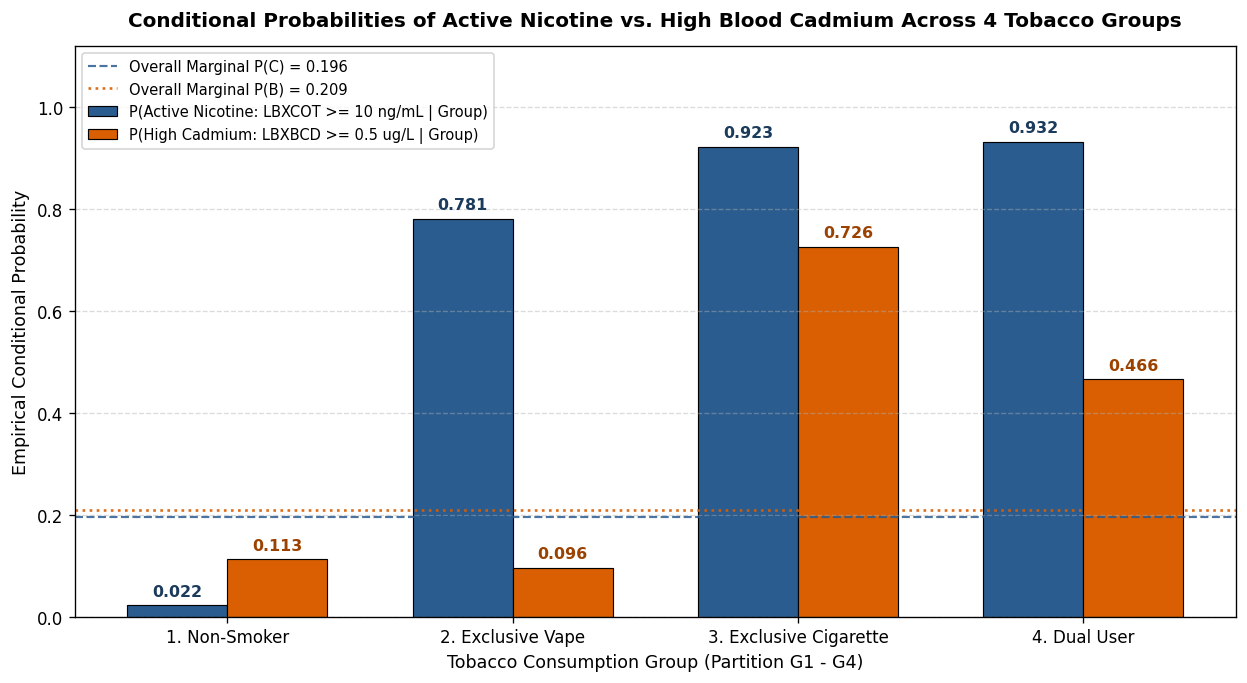

نمودار در مسیر زیر ذخیره شد: figures/p2_fig1_conditional_probs.png


In [6]:
df_cond_binary, df_cond_4groups = pe.compute_conditional_probabilities(df_p2)

print("=== جدول ۳-۱: احتمال شرطی کادمیوم بالا (B) و نیکوتین فعال (C) به شرط رویداد A و متمم آن ===")
display(df_cond_binary)

print("\n=== جدول ۳-۲: احتمال شرطی B و C به تفکیک هر چهار گروه افراز (G1 تا G4) ===")
display(df_cond_4groups)

fig_path = pe.plot_conditional_probabilities(df_p2, df_cond_4groups, output_dir="figures")
print("نمودار در مسیر زیر ذخیره شد:", fig_path)

In [7]:
import pandas as pd

indep_results = [
    pe.evaluate_independence(
        df_p2, "Event_A_Combustible", "Event_B_HighCd",
        "Pair 1: Combustible Smoker (A) & High Cadmium (B)"
    ),
    pe.evaluate_independence(
        df_p2, "Event_A_Combustible", "Event_C_ActiveCot",
        "Pair 2: Combustible Smoker (A) & Active Nicotine (C)"
    ),
    pe.evaluate_independence(
        df_p2, "Event_Male", "Event_B_HighCd",
        "Pair 3 (Contrast): Male Gender (M) & High Cadmium (B)"
    )
]

df_indep_audit = pd.DataFrame(indep_results)
print("=== جدول ۴-۱: بررسی استدلالی استقلال رویدادها (مقایسه P(E1 ∩ E2) با P(E1)*P(E2)) ===")
display(df_indep_audit)

=== جدول ۴-۱: بررسی استدلالی استقلال رویدادها (مقایسه P(E1 ∩ E2) با P(E1)*P(E2)) ===


,Event_Pair,N_Total,P(E1),P(E2),Observed_P(E1 n E2),Expected_Under_Indep_P(E1)*P(E2),Joint_Diff (Obs - Exp),Joint_Ratio (Obs / Exp),P(E2 | E1),P(E2 | E1^c),Cond_Shift [P(E2|E1) - P(E2)]
0,Pair 1: Combustible Smoker (A) & High Cadmium (B),4655,0.1665,0.2086,0.1151,0.0347,0.0804,3.32,0.6916,0.1121,0.4830
1,Pair 2: Combustible Smoker (A) & Active Nicoti...,4655,0.1665,0.1959,0.1538,0.0326,0.1212,4.72,0.9239,0.0505,0.7280
2,Pair 3 (Contrast): Male Gender (M) & High Cadm...,4655,0.4498,0.2086,0.0782,0.0938,-0.0156,0.83,0.1738,0.2370,-0.0348
